In [1]:
!pip install -q kagglehub
import kagglehub, glob, os
path = kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria")
data_dir = os.path.dirname(glob.glob(path + "/**/Parasitized", recursive=True)[0])
print(data_dir, os.listdir(data_dir))

Using Colab cache for faster access to the 'cell-images-for-detecting-malaria' dataset.
/kaggle/input/cell-images-for-detecting-malaria/cell_images ['Uninfected', 'Parasitized', 'cell_images']


In [3]:
import tensorflow as tf, json
IMG = (128, 128)
CLASSES = ["Parasitized", "Uninfected"]

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, class_names=CLASSES, validation_split=0.2, subset="training", seed=42,
    image_size=IMG, batch_size=64, label_mode="binary")
val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir, class_names=CLASSES, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG, batch_size=64, label_mode="binary")

class_names = train_ds.class_names
print(class_names)
json.dump(class_names, open("class_names.json", "w"))
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

Found 27558 files belonging to 2 classes.
Using 22047 files for training.
Found 27558 files belonging to 2 classes.
Using 5511 files for validation.
['Parasitized', 'Uninfected']


In [5]:
from tensorflow.keras import layers, models
base = tf.keras.applications.MobileNetV2(input_shape=IMG+(3,), include_top=False, weights="imagenet")
base.trainable = False

model = models.Sequential([
    layers.Input(IMG+(3,)),
    layers.RandomFlip("horizontal_and_vertical"),
    layers.Rescaling(1/127.5, offset=-1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
history = model.fit(train_ds, validation_data=val_ds, epochs=5)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
345/345 ━━━━━━━━━━━━━━━━━━━━ 118s 308ms/step - accuracy: 0.8532 - loss: 0.3331 - val_accuracy: 0.9136 - val_loss: 0.2241
Epoch 2/5
345/345 ━━━━━━━━━━━━━━━━━━━━ 26s 74ms/step - accuracy: 0.9038 - loss: 0.2427 - val_accuracy: 0.9238 - val_loss: 0.2008
Epoch 3/5
345/345 ━━━━━━━━━━━━━━━━━━━━ 26s 77ms/step - accuracy: 0.9122 - loss: 0.2277 - val_accuracy: 0.9251 - val_loss: 0.1937
Epoch 4/5
345/345 ━━━━━━━━━━━━━━━━━━━━ 26s 76ms/step - accuracy: 0.9141 - loss: 0.2212 - val_accuracy: 0.9278 - val_loss: 0.1886
Epoch 5/5
345/345 ━━━━━━━━━━━━━━━━━━━━ 26s 74ms/step - accuracy: 0.9163 - loss: 0.2180 - val_accuracy: 0.9285 - val_loss: 0.1877


87/87 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9285 - loss: 0.1877
Validation accuracy: 0.92850661277771
['Parasitized_C101P62ThinF_IMG_20150918_151942_cell_60.png', 'Uninfected_C119P80ThinF_IMG_20151002_124304_cell_112.png', 'Uninfected_C39P4thinF_original_IMG_20150622_111723_cell_33.png', 'Parasitized_C52P13thinF_IMG_20150725_124830_cell_174.png', 'Parasitized_C99P60ThinF_IMG_20150918_141001_cell_93.png', 'Parasitized_C162P123ThinF_IMG_20151116_102655_cell_163.png', 'Uninfected_C203ThinF_IMG_20151029_102123_cell_51.png', 'Parasitized_C99P60ThinF_IMG_20150918_141001_cell_133.png', 'Uninfected_C101P62ThinF_IMG_20150918_151149_cell_63.png', 'Uninfected_C238NThinF_IMG_20151207_114038_cell_84.png']


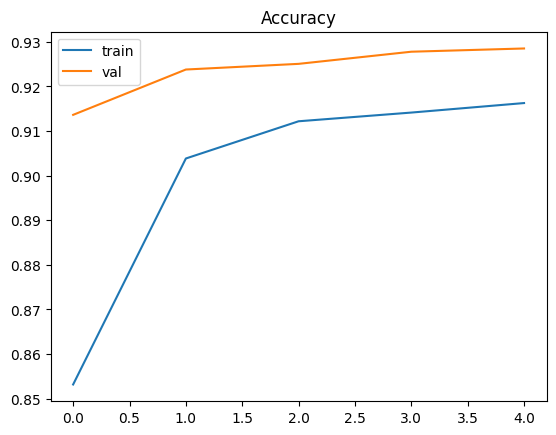

In [6]:
loss, acc = model.evaluate(val_ds)
print("Validation accuracy:", acc)

import matplotlib.pyplot as plt, os, shutil
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="val")
plt.legend(); plt.title("Accuracy"); plt.savefig("accuracy_plot.png")

model.save("malaria_model.keras")

# demo ke liye chhoti sample images (sirf png)
os.makedirs("sample_images", exist_ok=True)
for c in class_names:
    pngs = [f for f in os.listdir(f"{data_dir}/{c}") if f.lower().endswith(".png")][:5]
    for f in pngs:
        shutil.copy(f"{data_dir}/{c}/{f}", f"sample_images/{c}_{f}")
print(os.listdir("sample_images"))

In [7]:
import shutil
from google.colab import files
shutil.make_archive("sample_images", "zip", "sample_images")
files.download("malaria_model.keras")
files.download("class_names.json")
files.download("accuracy_plot.png")
files.download("sample_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
print(tf.__version__)

2.21.0
